# Project.1 - Pass-01, Transaction Data




## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


### Load Pandas, Numpy, and Matplotlib modules

In [ ]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

### Load data Train.csv from AWS S3[link text](https://)

In [ ]:
# Load data Train.csv from AWS S3
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.csv'
url

df = pd.read_csv(
    url,
    usecols=range(5),
    nrows=1_000,
)

df

,Unnamed: 0,ID_code,target,var_0,var_1
0,0,train_0,0,8.9255,-6.7863
1,1,train_1,0,11.5006,-4.1473
2,2,train_2,0,8.6093,-2.7457
3,3,train_3,0,11.0604,-2.1518
4,4,train_4,0,9.8369,-1.4834
...,...,...,...,...,...
995,995,train_995,0,10.5429,-3.1313
996,996,train_996,0,12.9541,-3.5607
997,997,train_997,0,4.2341,-8.5367
998,998,train_998,0,18.5600,2.3607


In [ ]:
# Look at the first few rows
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1
0,0,train_0,0,8.9255,-6.7863
1,1,train_1,0,11.5006,-4.1473
2,2,train_2,0,8.6093,-2.7457
3,3,train_3,0,11.0604,-2.1518
4,4,train_4,0,9.8369,-1.4834


In [ ]:
# Look at the last few rows
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1
995,995,train_995,0,10.5429,-3.1313
996,996,train_996,0,12.9541,-3.5607
997,997,train_997,0,4.2341,-8.5367
998,998,train_998,0,18.5600,2.3607
999,999,train_999,0,10.5495,2.3825


In [ ]:
# Shape of the dataframe
df.shape

(1000, 5)

In [ ]:
# Size of the dataframe
df.size

5000

### Summary Meta-Data

In [ ]:
# Display meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  1000 non-null   int64  
 1   ID_code     1000 non-null   object 
 2   target      1000 non-null   int64  
 3   var_0       1000 non-null   float64
 4   var_1       1000 non-null   float64
dtypes: float64(2), int64(2), object(1)
memory usage: 39.2+ KB


### Summary Statistics

In [ ]:
# Display summary statistics
df.describe()

,Unnamed: 0,target,var_0,var_1
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,0.097000,10.647679,-1.648351
std,288.819436,0.296106,3.046156,4.133810
min,0.000000,0.000000,2.825300,-13.202600
25%,249.750000,0.000000,8.418225,-4.858000
50%,499.500000,0.000000,10.460250,-1.760000
75%,749.250000,0.000000,12.656275,1.394700
max,999.000000,1.000000,19.122300,8.416000


### NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

### Target Value Counts

Binary numerical classification and no nulls.

In [ ]:
# Value_counts on target ; include nulls
df['target'].value_counts(dropna=False)

,count
target,
0,903
1,97


### Normalize The Data

In [ ]:
# Normalized value_counts on target ; include nulls
df['target'].value_counts(dropna=False, normalize=True)

,proportion
target,
0,0.903
1,0.097


### Nulls
No imputation because no nulls.

In [ ]:
# Look for nulls
df.isnull().sum().sort_values(ascending=False)

,0
Unnamed: 0,0
ID_code,0
target,0
var_0,0
var_1,0


Column Data Types

In [ ]:
# Display data types
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,int64
var_0,float64
var_1,float64


In [ ]:
# Number of unique elements in a column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,1000
ID_code,1000
var_1,995
var_0,994
target,2


## Data Cleaning


### Backup #1

In [ ]:
# Make backup
df_bak = df.copy()

In [ ]:
# Restore from backup
df = df_bak.copy()

### Keep Only the Target and Features

In [ ]:
# Select the target and features
df = df[['target','var_0','var_1']]
df

,target,var_0,var_1
0,0,8.9255,-6.7863
1,0,11.5006,-4.1473
2,0,8.6093,-2.7457
3,0,11.0604,-2.1518
4,0,9.8369,-1.4834
...,...,...,...
995,0,10.5429,-3.1313
996,0,12.9541,-3.5607
997,0,4.2341,-8.5367
998,0,18.5600,2.3607


### Backup #2

In [ ]:
# Make 2nd backup
df_bak_2 = df.copy()

In [ ]:
# Restore from 2nd backup
df = df_bak_2.copy()

## Exploratory Data Analysis


### Normal Distribution of Features: Histogram & Box Plot

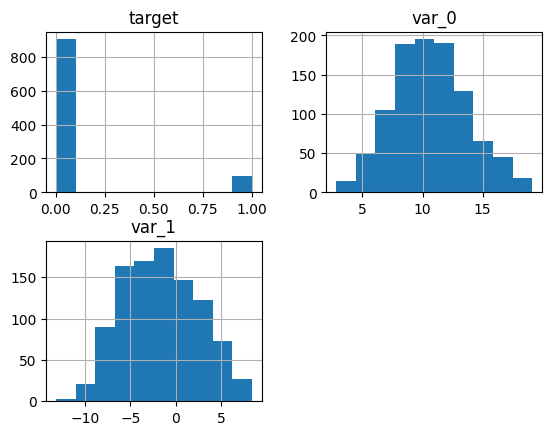

In [ ]:
df.hist() ;

<Axes: >

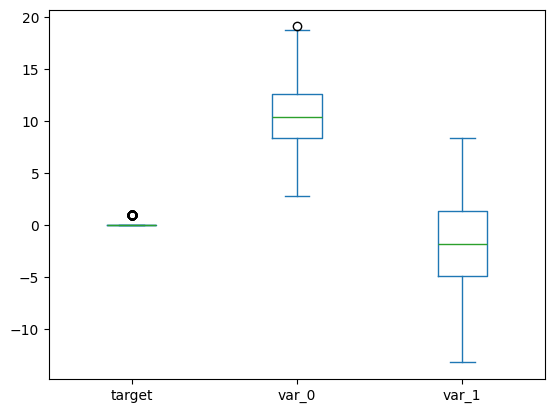

In [ ]:
df.plot(kind='box')

### Correlation: Independence of Features

In [ ]:
# Calculate a correlation matrix
iso_features = df[['var_0','var_1']]

corr_mat = iso_features.corr()

corr_mat

,var_0,var_1
var_0,1.000000,0.016709
var_1,0.016709,1.000000


Text(0.5, 23.52222222222222, 'Features')

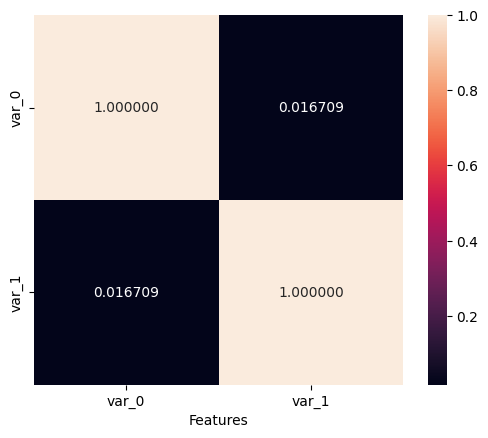

In [ ]:
# Heatmap of the correlation matrix
sns.heatmap(
    corr_mat,
    square=True,
    annot=True,
    fmt='2f',
    cbar=True,
)

plt.xlabel('Features')
plt.xlabel('Features')

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [ ]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Processing



### Single Cross Validation ( CV )

#### Two data sets with target and features

In [ ]:
# Split data frame into target and features
target_col = 'target'
target = df[ target_col]
features = df.drop(columns=[target_col])

In [ ]:
target

,target
0,0
1,0
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [ ]:
features

,var_0,var_1
0,8.9255,-6.7863
1,11.5006,-4.1473
2,8.6093,-2.7457
3,11.0604,-2.1518
4,9.8369,-1.4834
...,...,...
995,10.5429,-3.1313
996,12.9541,-3.5607
997,4.2341,-8.5367
998,18.5600,2.3607


#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [ ]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets you created in step 10 into training and testing subsets, i.e. train-test split.

In [ ]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [ ]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(750, 2)
<class 'pandas.core.frame.DataFrame'>
(250, 2)
<class 'pandas.core.frame.DataFrame'>
(750,)
<class 'pandas.core.series.Series'>
(250,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [ ]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

GaussianNB()

#### Test the model ( predict ) using the testing subset of the dataset.

In [ ]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0])

#### Calculate and report the accuracy.

In [ ]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

88.4

#### Present a confusion matrix and heatmap

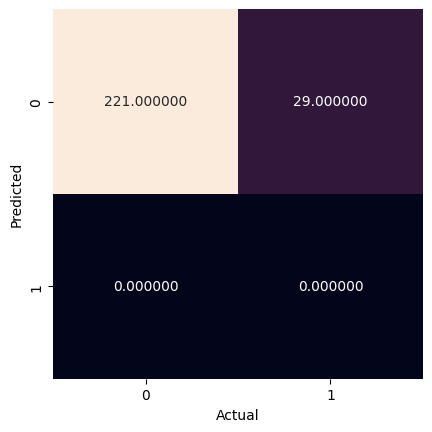

In [ ]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Present the results of a Classification Report (sklearn.metrics.classification_report).

In [ ]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

           0       0.88      1.00      0.94       221
           1       0.00      0.00      0.00        29

    accuracy                           0.88       250
   macro avg       0.44      0.50      0.47       250
weighted avg       0.78      0.88      0.83       250



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Data Visualization/Communication of Results


### Data Visualization

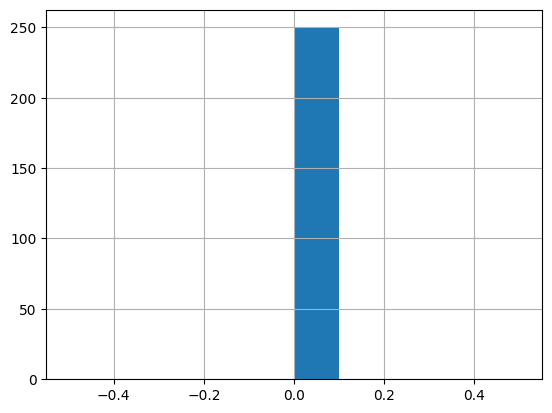

In [ ]:
pd.Series(pred_results).hist() ;

### Conclusion

- var_0 and var_1 gave us 88% accuracy
- Great at predicting no-transactions
- Bad at predicting a successful transaction

### Future work


- For Pass-02, use the first 20 columns (up from 5 columns)
- Balance the dataset (way more unsuccessful transactions vs. successful transactions